In [1]:
import numpy as np
import random
import os
from src.optim_utils import *
from src.plot_utils import *

## Part A

$$f(x) = \frac{1}{2}x^TAx, \ A = diag(1, \kappa)$$

1. Run GD and Newton for each kappa. Fill in a table with kappa down the rows and GD and Newton iteration counts across the columns.
2. Plot GD iterations against kappa on log-log axes.
3. Answer in the notebook: how does GD's iteration count scale with kappa? Why does Newton's count not change with kappa? Hint: write out the Newton step for this f.

In [2]:
kappas = [1.0, 10.0, 100.0, 1000.0]
x_init = np.array([1.0, 1.0])

**Gradient Descent**

In [3]:
gd_xs, gd_fn_vals, gd_grad_norms, gd_step_sizes, gd_condition_nos, gd_num_iters = [], [], [], [], [], []
for kappa in kappas:
    fn = lambda x: quad_fn(x, k=kappa)
    grad_fn = lambda x: quad_grad(x, k=kappa)
    hess_fn = lambda x: quad_hessian(x, k=kappa)
    
    xs, fn_vals, grad_norms, step_sizes, condition_nos = gradient_descent(x_init, fn, grad_fn, hess_fn, max_iter=gd_max_iter, 
                                                     min_grad_norm=min_grad_norm, default_step_size=default_step_size,
                                                     use_line_search=True)
    
    gd_xs.append(xs)
    gd_fn_vals.append(fn_vals)
    gd_grad_norms.append(grad_norms)
    gd_step_sizes.append(step_sizes)
    gd_condition_nos.append(condition_nos)
    gd_num_iters.append(len(fn_vals))
    
    print(f'kappa: {kappa}, # iters: {len(fn_vals)}')

kappa: 1.0, # iters: 2
kappa: 10.0, # iters: 59
kappa: 100.0, # iters: 637
kappa: 1000.0, # iters: 6988


**Newton Method**

In [4]:
nw_xs, nw_fn_vals, nw_grad_norms, nw_step_sizes, nw_condition_nos = [], [], [], [], []
nw_lambdas, nw_num_iters, nw_num_shifts = [], [], []
for kappa in kappas:
    fn = lambda x: quad_fn(x, k=kappa)
    grad_fn = lambda x: quad_grad(x, k=kappa)
    hess_fn = lambda x: quad_hessian(x, k=kappa)
    
    xs, fn_vals, grad_norms, step_sizes, condition_nos, lambdas, num_shifts = newton_method(x_init, fn, grad_fn, hess_fn, max_iter=newton_max_iter, 
                                                      min_grad_norm=min_grad_norm, default_step_size=default_step_size,
                                                      use_line_search=True, safeguard=False, get_slopes=False)
    
    nw_xs.append(xs)
    nw_fn_vals.append(fn_vals)
    nw_grad_norms.append(grad_norms)
    nw_step_sizes.append(step_sizes)
    nw_condition_nos.append(condition_nos)
    nw_lambdas.append(lambdas)
    nw_num_shifts.append(num_shifts)
    nw_num_iters.append(len(fn_vals))
    
    print(f'kappa: {kappa}, # iters: {len(fn_vals)}')

kappa: 1.0, # iters: 2
kappa: 10.0, # iters: 2
kappa: 100.0, # iters: 2
kappa: 1000.0, # iters: 2


**Plots and Tables**

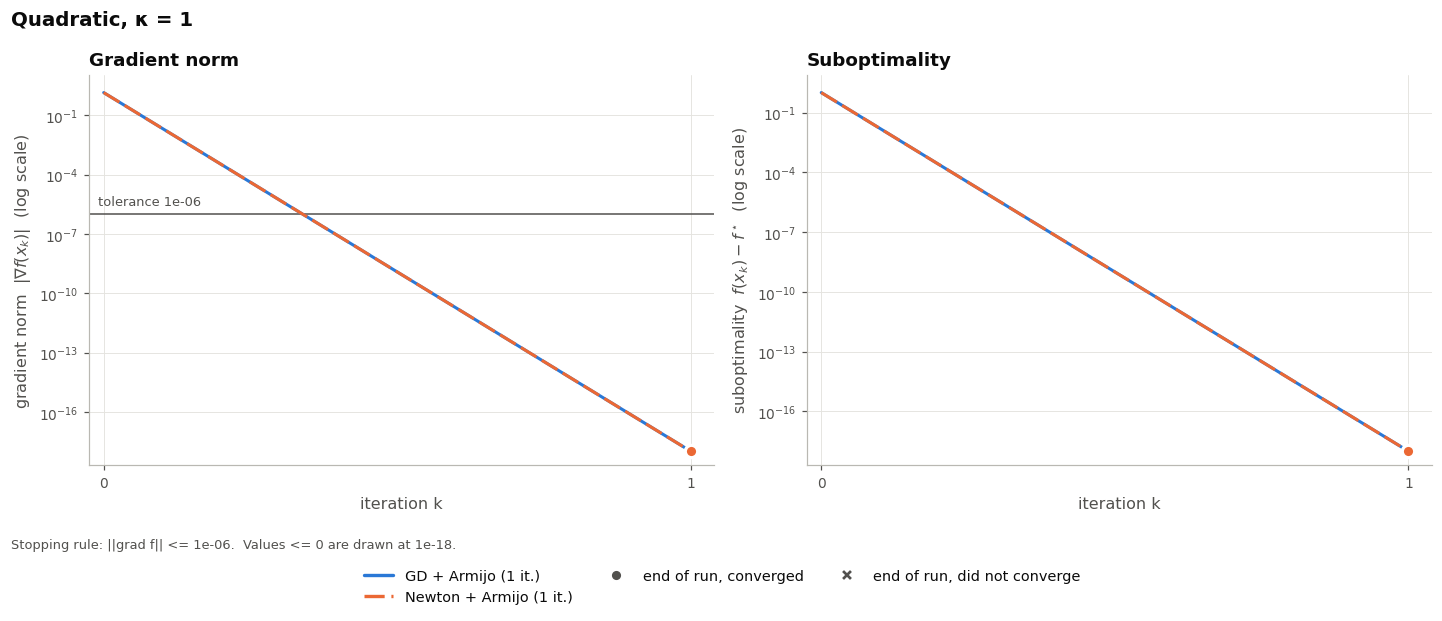

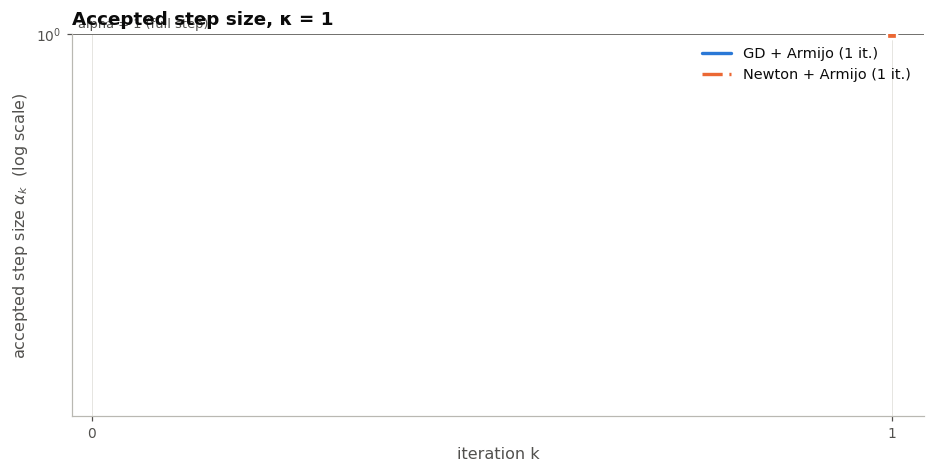

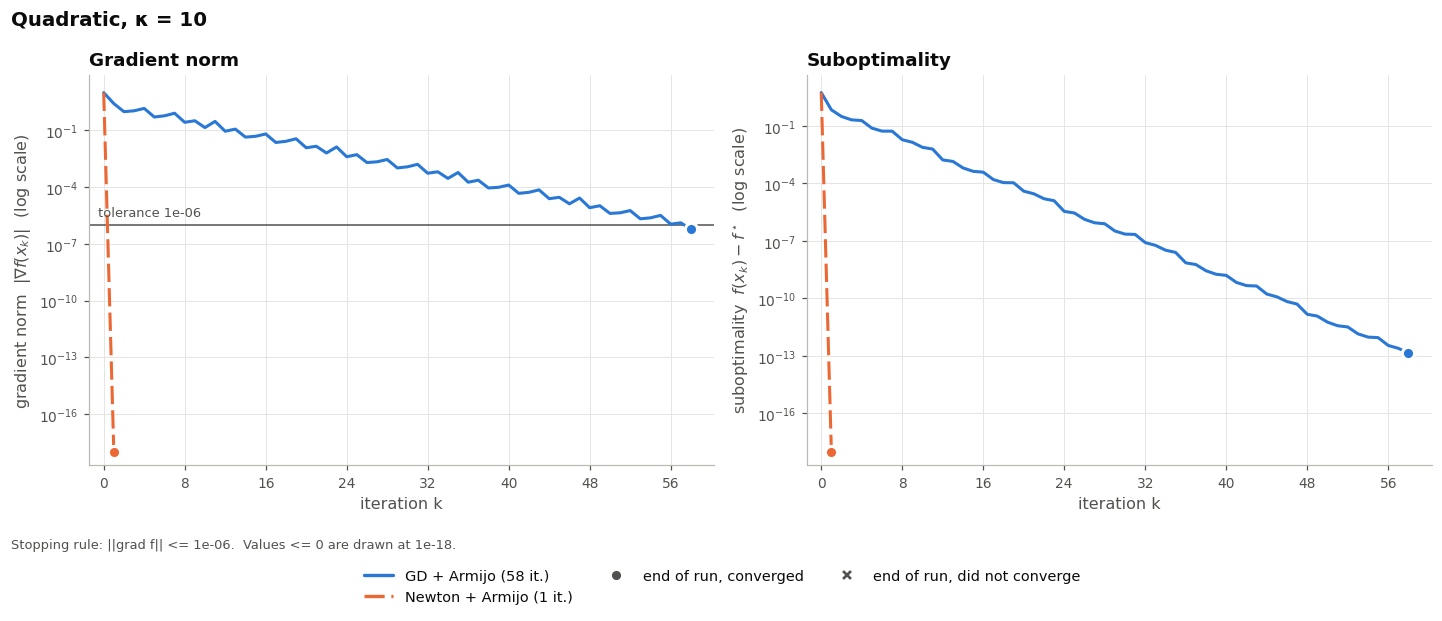

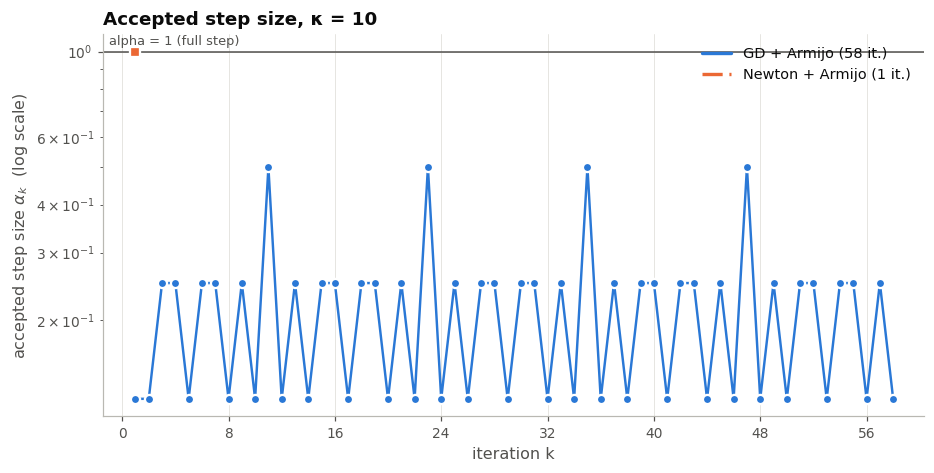

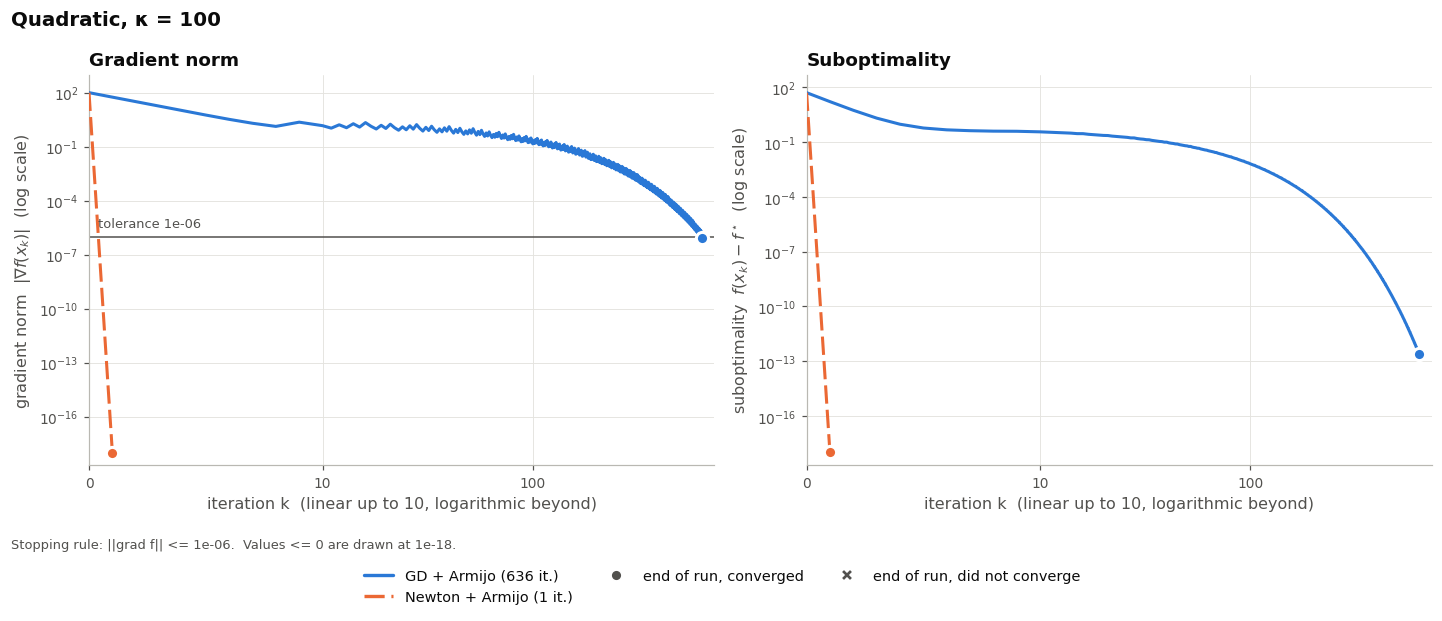

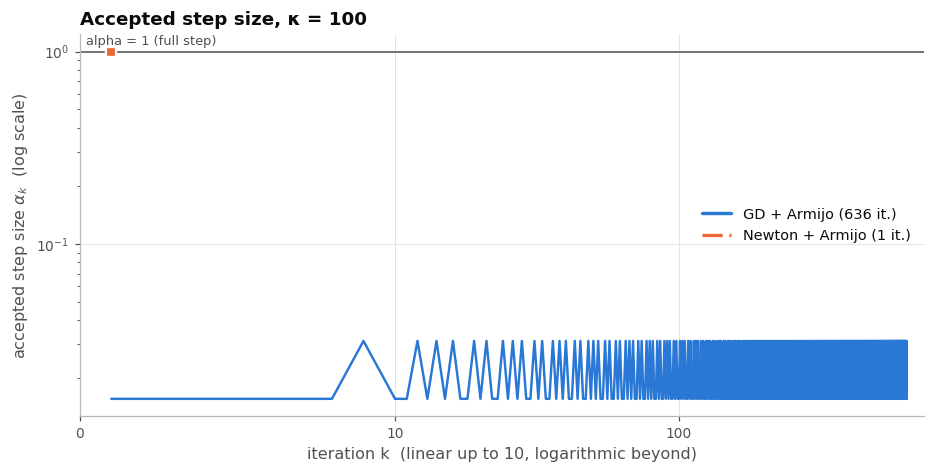

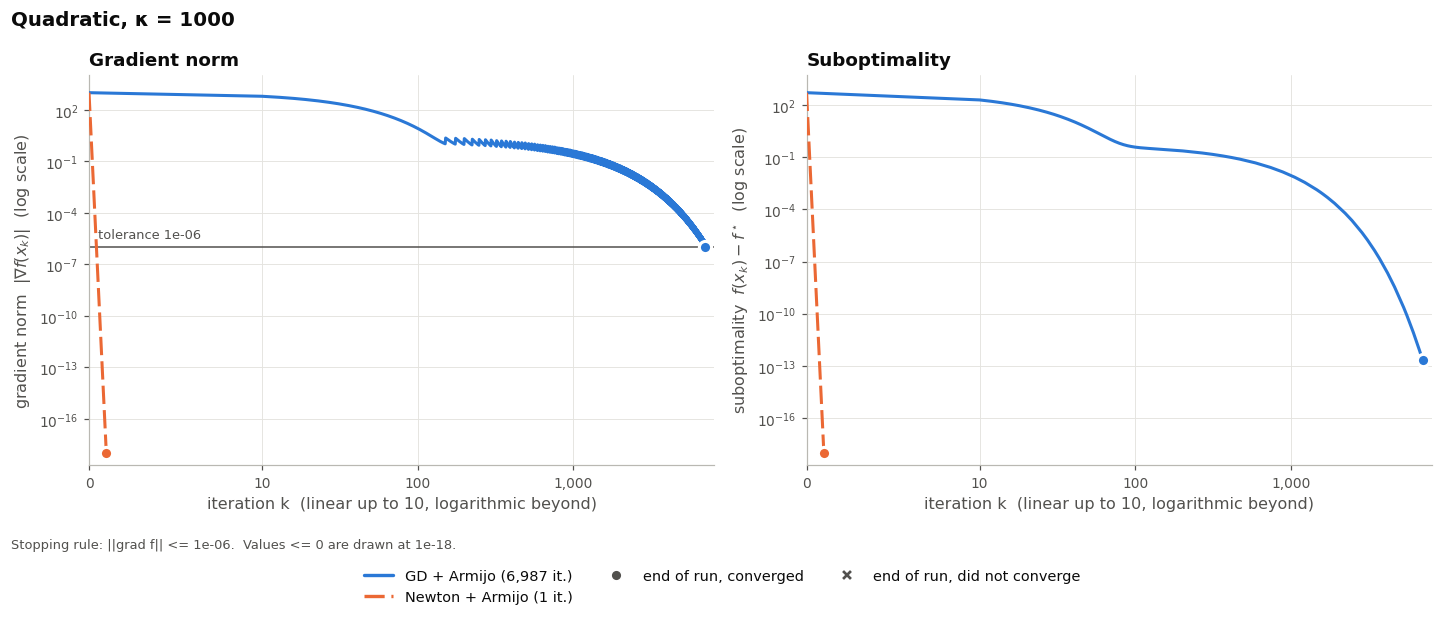

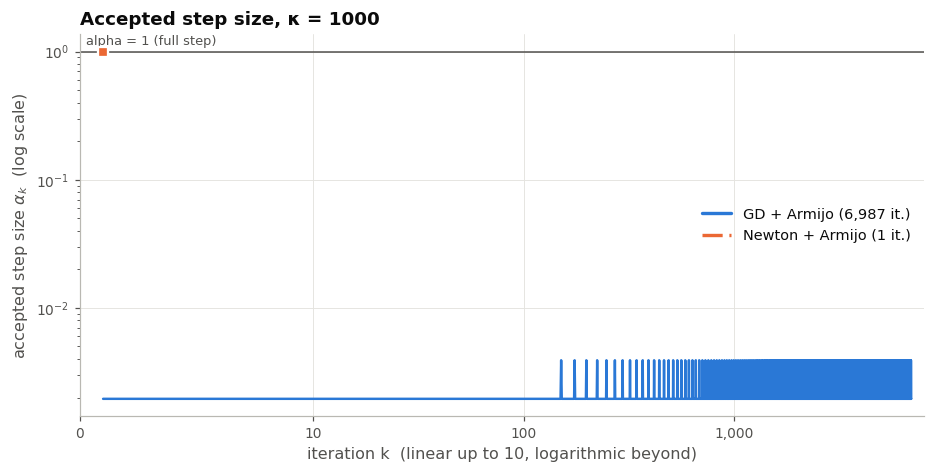

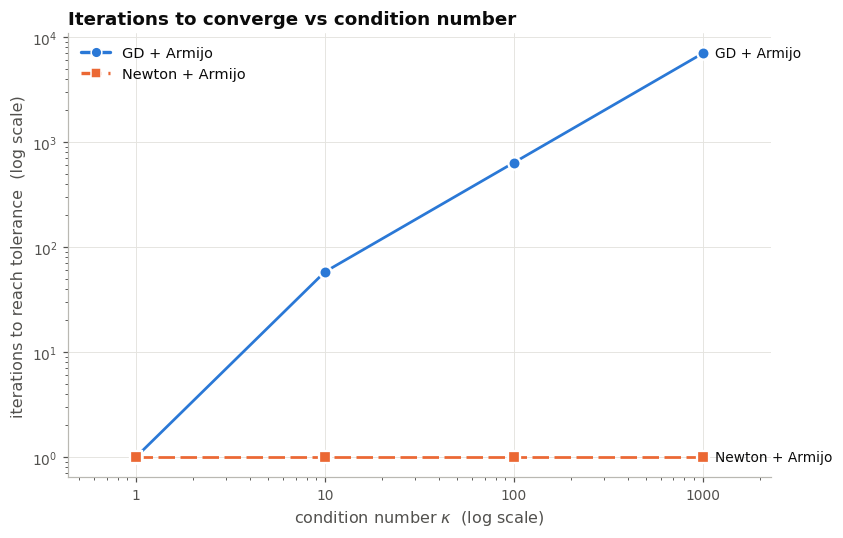

,Method,Start,Iterations,Converged,Final f,Final ||grad||,Tolerance,Step rule,Iteration cap,kappa
0,GD + Armijo,"(1, 1)",1,yes,0.000e+00,0.000e+00,1e-06,fixed alpha = 1,200000,1
1,Newton + Armijo,"(1, 1)",1,yes,0.000e+00,0.000e+00,1e-06,fixed alpha = 1,200000,1
2,GD + Armijo,"(1, 1)",58,yes,1.438e-13,6.030e-07,1e-06,"backtracking (alpha in [0.125, 0.5])",200000,10
3,Newton + Armijo,"(1, 1)",1,yes,0.000e+00,0.000e+00,1e-06,fixed alpha = 1,200000,10
4,GD + Armijo,"(1, 1)",636,yes,2.369e-13,8.765e-07,1e-06,"backtracking (alpha in [0.0156, 0.0312])",200000,100
5,Newton + Armijo,"(1, 1)",1,yes,0.000e+00,0.000e+00,1e-06,fixed alpha = 1,200000,100
6,GD + Armijo,"(1, 1)",6987,yes,2.264e-13,9.881e-07,1e-06,"backtracking (alpha in [0.00195, 0.00391])",200000,1000
7,Newton + Armijo,"(1, 1)",1,yes,0.000e+00,0.000e+00,1e-06,fixed alpha = 1,200000,1000


In [5]:
kappas = [1, 10, 100, 1000]
tol, cap = 1e-6, 200000          # use the values your runs actually used

all_runs, rows = [], []
for i, k in enumerate(kappas):
    gd = make_run("GD + Armijo",                 # same name for every kappa, so colours match across figures
                  gd_xs[i],                      # iterates incl. x0, length K+1
                  fs=gd_fn_vals[i],                   # f(x_k), length K+1
                  gnorms=gd_grad_norms[i],               # ||grad f(x_k)||, length K+1
                  alphas=gd_step_sizes[i],            # accepted step sizes, length K (optional)
                  tol=tol, max_iter=cap, meta={"kappa": k})
    nt = make_run("Newton + Armijo",
                  nw_xs[i], fs=nw_fn_vals[i], gnorms=nw_grad_norms[i], alphas=nw_step_sizes[i],
                  tol=tol, max_iter=cap, meta={"kappa": k})

    plot_convergence_panel([gd, nt], title=f"Quadratic, κ = {k}",
                           save=f"partA_conv_kappa{k}.png")   # grad norm and f - f* (f* = 0 here)
    plot_step_sizes([gd, nt], title=f"Accepted step size, κ = {k}")   # optional

    all_runs += [gd, nt]
    rows += [dict(kappa=k, method=r.name, iterations=r.iterations, converged=r.converged)
             for r in (gd, nt)]

plot_kappa_scaling(rows, save="partA_kappa_scaling.png")   # iterations vs κ, log-log
summary_table(all_runs)                                    # one row per (method, κ); κ shows as a column

GD's iterations seem to have an power law relation with the condition number (almost linear in log-log plot). 

For Newton's Method, $\nabla^2 f(x) = A$ and $\nabla f(x) = Ax$. So, one iteration gives $x_1 = x_0 - x_0 = 0$. Since $A$ is a positive definite matrix, Newton's Method converges in 1 iteration.

## Part B

$$f(x, y) = (a - x)^2 + b(y - x^2)^2$$

$$H(x, y) = \begin{bmatrix}12bx^2 - 4by + 2 & -4bx \\ -4bx & 2b\end{bmatrix}$$

Use the starting points (-1.2, 1), (2, 2), (0, 1), (0, 2), (0.5, 1.0), and (-0.5, 1.0). Run three methods from each:
1. Plain Newton: d = solve(H, -g), then Armijo backtracking. At every iteration also record g.d and whether H is positive definite. Note where it fails or stalls.
2. Safeguarded Newton: the recipe below.
3. GD with Armijo, same tolerance, same starts.

In [6]:
starts = [np.array([-1.2, 1.0]), np.array([2.0, 2.0]), np.array([0.0, 1.0]),
         np.array([0.0, 2.0]), np.array([0.5, 1.0]), np.array([-0.5, 1.0])]
fn = rosenbrock
grad_fn = grad_rosenbrock
hess_fn = hessian_rosenbrock

**Newton Method**

In [7]:
nwp_xs, nwp_fn_vals, nwp_grad_norms, nwp_step_sizes, nwp_condition_nos = [], [], [], [], []
nwp_lambdas, nwp_shifts, nwp_num_iters, nwp_slopes = [], [], [], []

for x_init in starts:   
    xs, fn_vals, grad_norms, step_sizes, condition_nos, lambdas, num_shifts, slopes = newton_method(x_init, fn, grad_fn, hess_fn, max_iter=newton_max_iter, 
                                                          min_grad_norm=min_grad_norm, default_step_size=default_step_size,
                                                          use_line_search=True, safeguard=False, get_slopes=True)
    
    nwp_xs.append(xs)
    nwp_fn_vals.append(fn_vals)
    nwp_grad_norms.append(grad_norms)
    nwp_step_sizes.append(step_sizes)
    nwp_condition_nos.append(condition_nos)
    nwp_num_iters.append(len(fn_vals))
    nwp_lambdas.append(lambdas)
    nwp_shifts.append(num_shifts)
    nwp_slopes.append(slopes)
    
    print(f'start: {[x_init[0], x_init[1]]}, # iters: {len(fn_vals)}')

start: [-1.2, 1.0], # iters: 22
start: [2.0, 2.0], # iters: 16
start: [0.0, 1.0], # iters: 16
start: [0.0, 2.0], # iters: 16
start: [0.5, 1.0], # iters: 12
start: [-0.5, 1.0], # iters: 18


**Safeguarded Newton Method**

In [8]:
nws_xs, nws_fn_vals, nws_grad_norms, nws_step_sizes, nws_condition_nos = [], [], [], [], []
nws_lambdas, nws_shifts, nws_num_iters, nws_slopes = [], [], [], []

for x_init in starts:   
    xs, fn_vals, grad_norms, step_sizes, condition_nos, lambdas, num_shifts, slopes = newton_method(x_init, fn, grad_fn, hess_fn, max_iter=newton_max_iter, 
                                                          min_grad_norm=min_grad_norm, default_step_size=default_step_size,
                                                          use_line_search=True, safeguard=True, get_slopes=True)
    
    nws_xs.append(xs)
    nws_fn_vals.append(fn_vals)
    nws_grad_norms.append(grad_norms)
    nws_step_sizes.append(step_sizes)
    nws_condition_nos.append(condition_nos)
    nws_num_iters.append(len(fn_vals))
    nws_lambdas.append(lambdas)
    nws_shifts.append(num_shifts)
    nws_slopes.append(slopes)
    
    print(f'start: {[x_init[0], x_init[1]]}, # iters: {len(fn_vals)}')

start: [-1.2, 1.0], # iters: 22
start: [2.0, 2.0], # iters: 16
start: [0.0, 1.0], # iters: 15
start: [0.0, 2.0], # iters: 10
start: [0.5, 1.0], # iters: 7
start: [-0.5, 1.0], # iters: 21


**Gradient Descent**

In [9]:
gd_xs, gd_fn_vals, gd_grad_norms, gd_step_sizes, gd_condition_nos, gd_num_iters = [], [], [], [], [], []

for x_init in starts:   
    xs, fn_vals, grad_norms, step_sizes, condition_nos = gradient_descent(x_init, fn, grad_fn, hess_fn, max_iter=gd_max_iter, 
                                                     min_grad_norm=min_grad_norm, default_step_size=default_step_size,
                                                     use_line_search=True)
    
    gd_xs.append(xs)
    gd_fn_vals.append(fn_vals)
    gd_grad_norms.append(grad_norms)
    gd_step_sizes.append(step_sizes)
    gd_condition_nos.append(condition_nos)
    gd_num_iters.append(len(fn_vals))
    
    print(f'start: {[x_init[0], x_init[1]]}, # iters: {len(fn_vals)}')

start: [-1.2, 1.0], # iters: 13757
start: [2.0, 2.0], # iters: 17686
start: [0.0, 1.0], # iters: 14815
start: [0.0, 2.0], # iters: 14835
start: [0.5, 1.0], # iters: 14430
start: [-0.5, 1.0], # iters: 14682


**Plots and Tables**

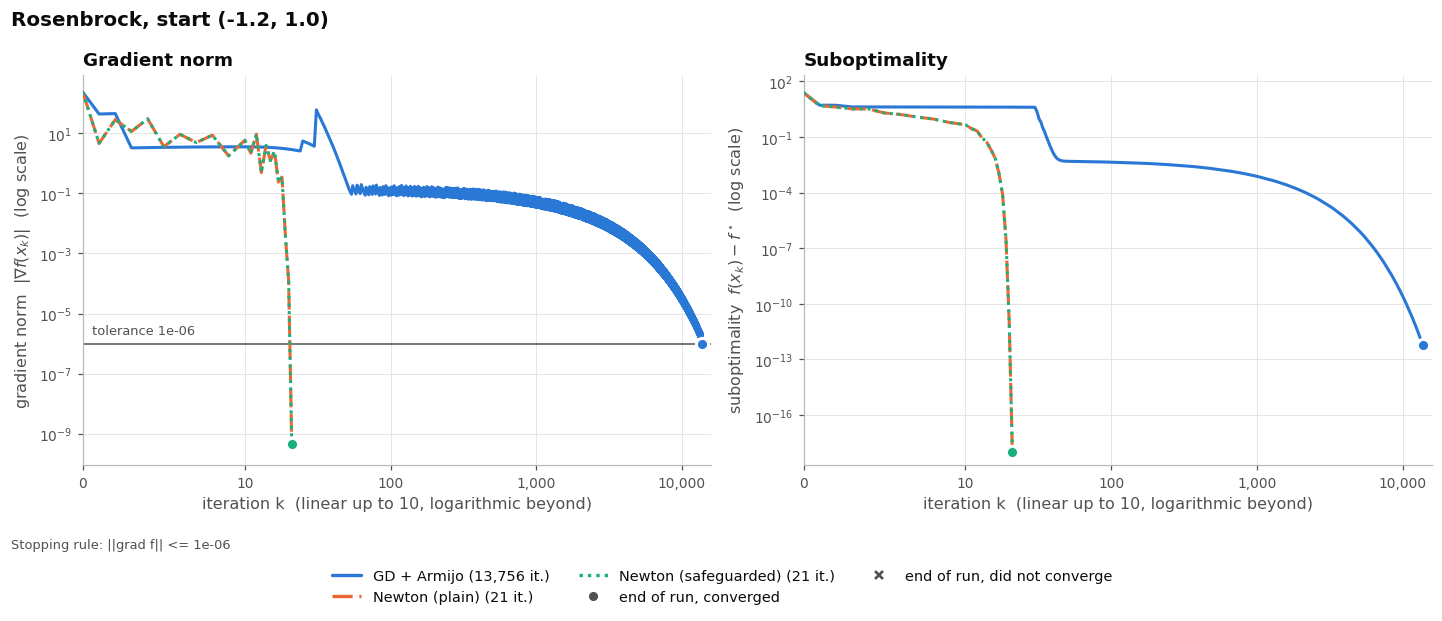

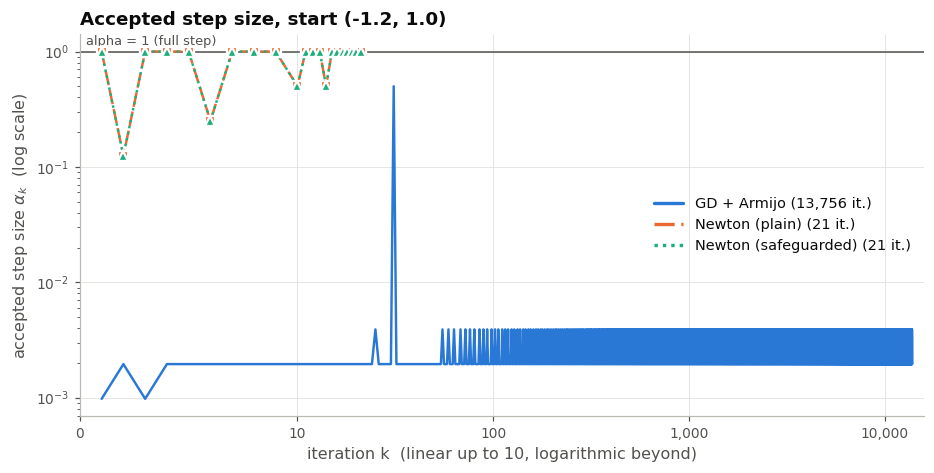

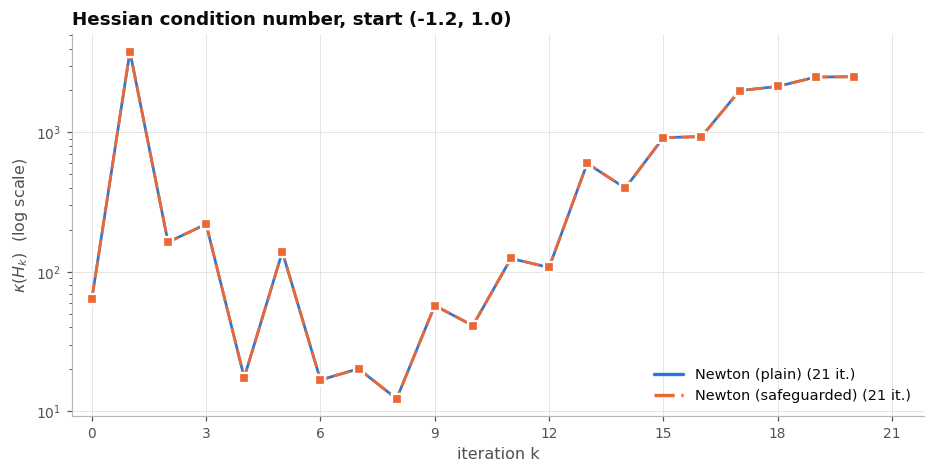

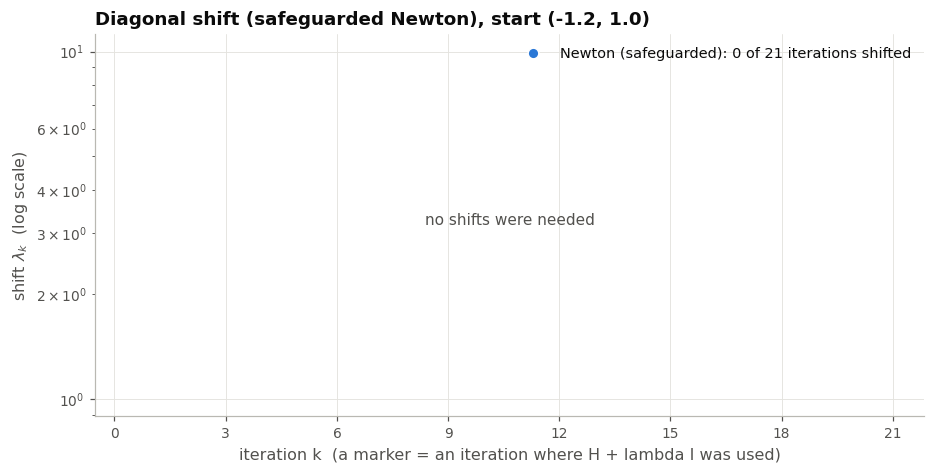

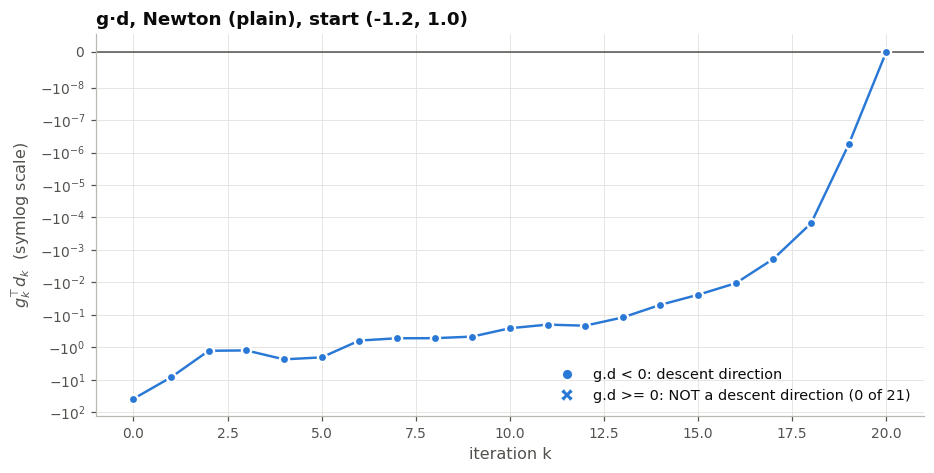

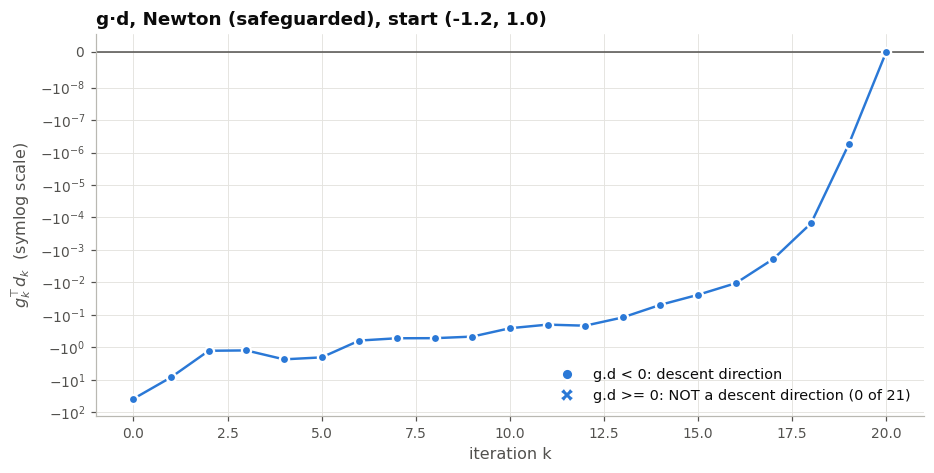

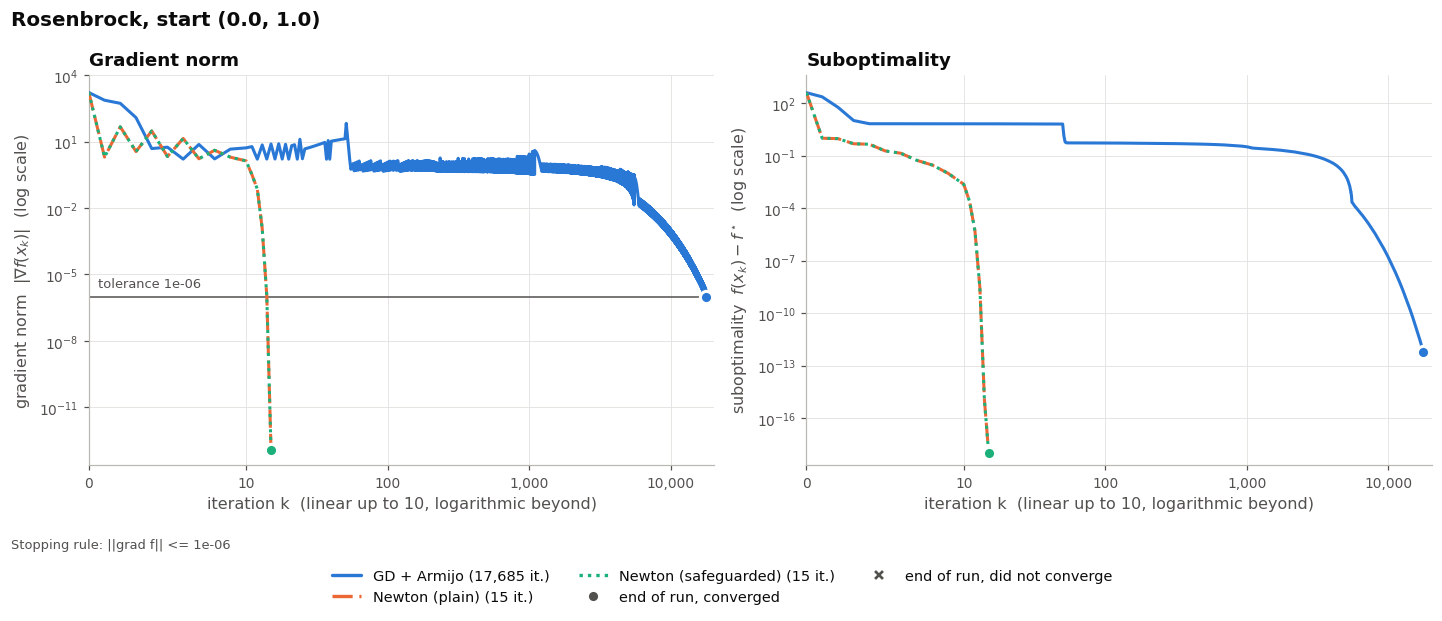

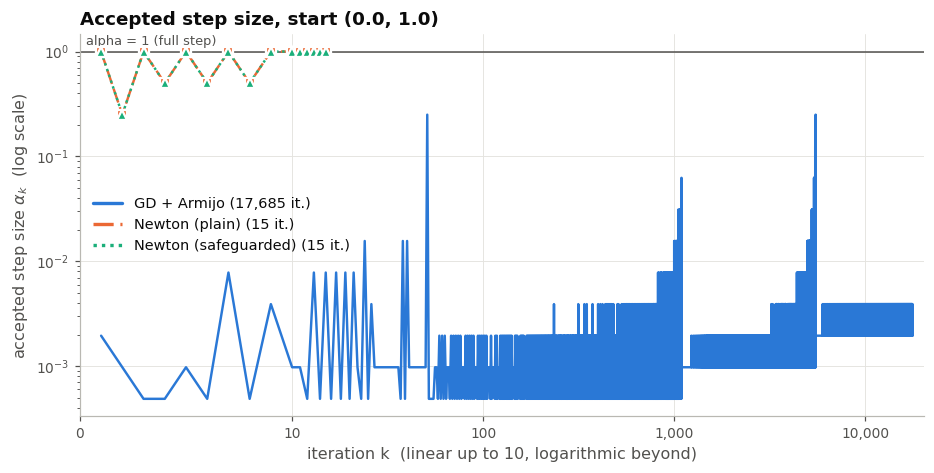

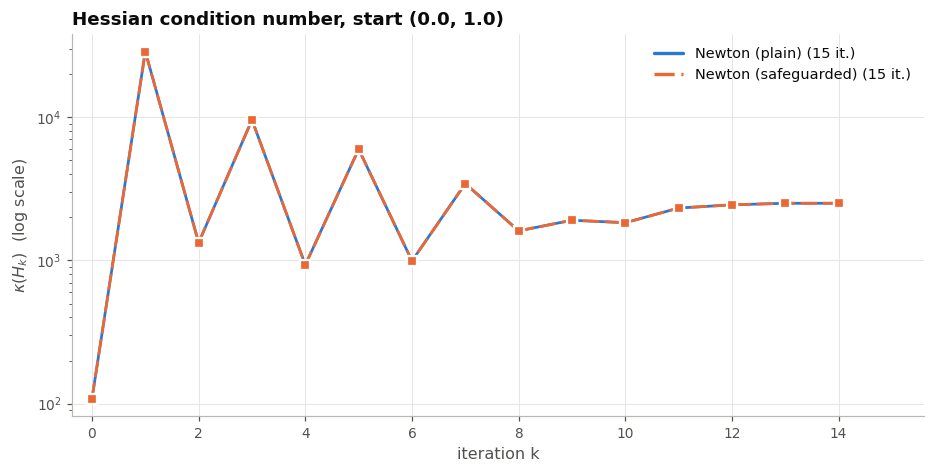

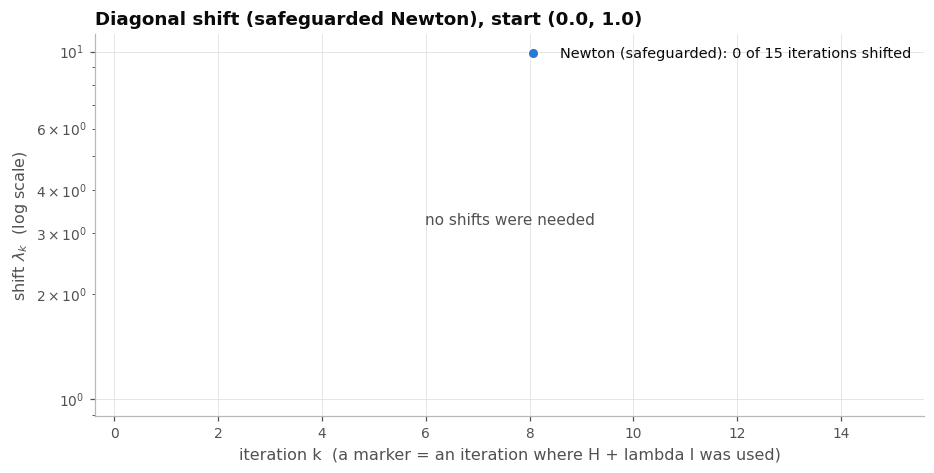

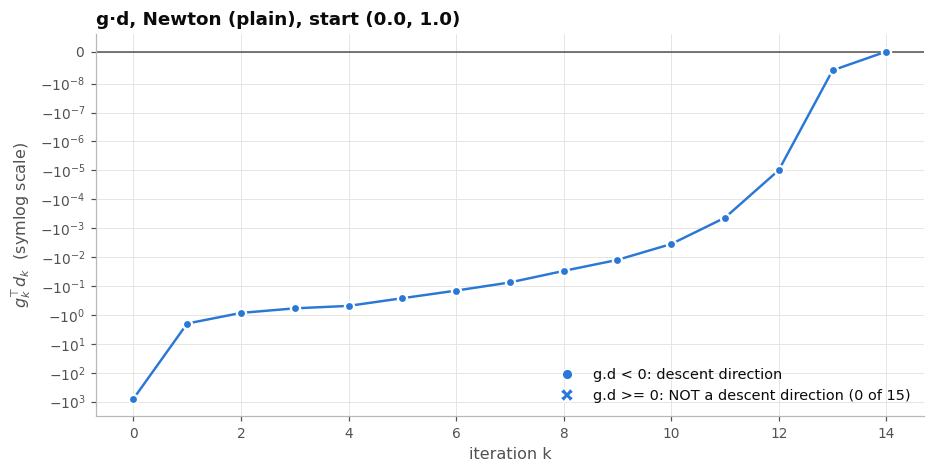

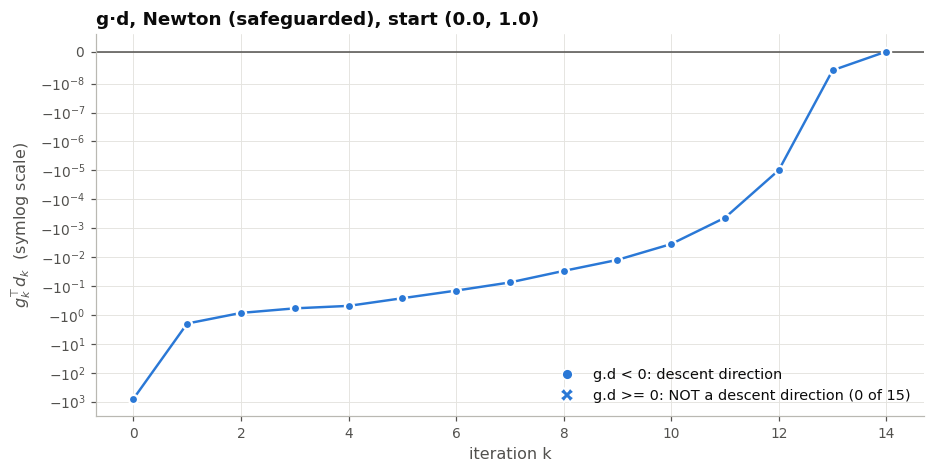

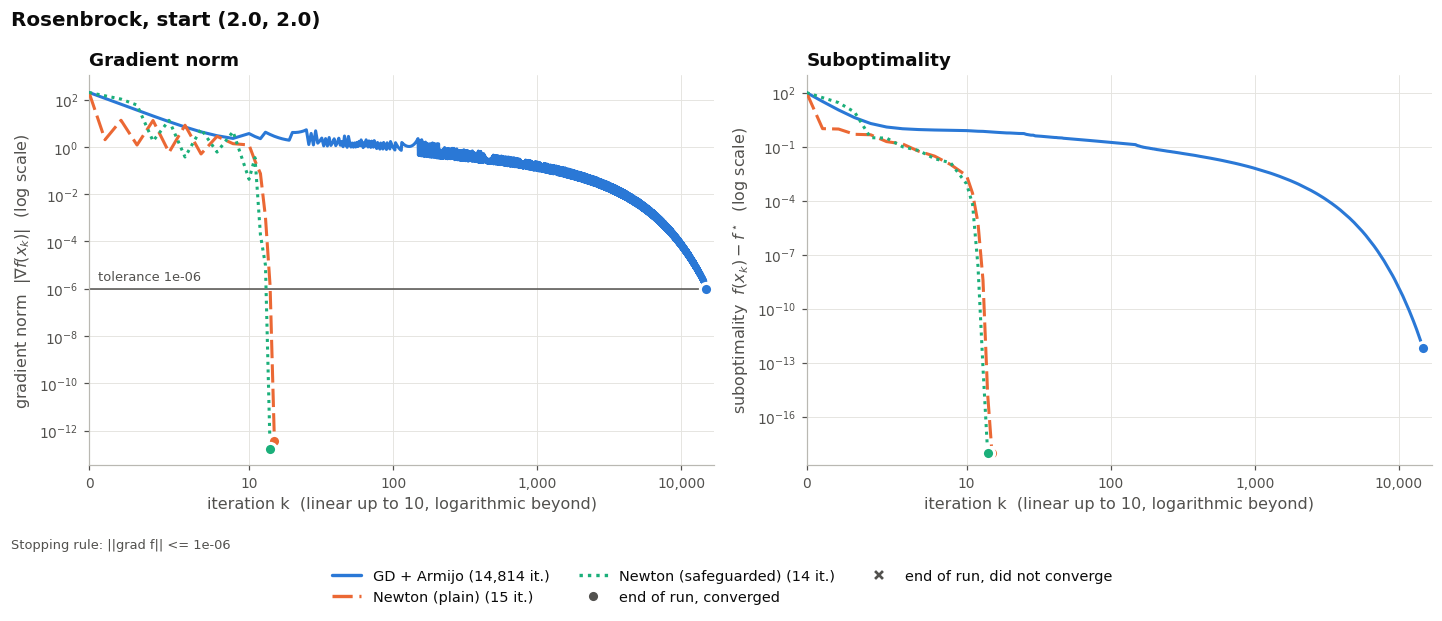

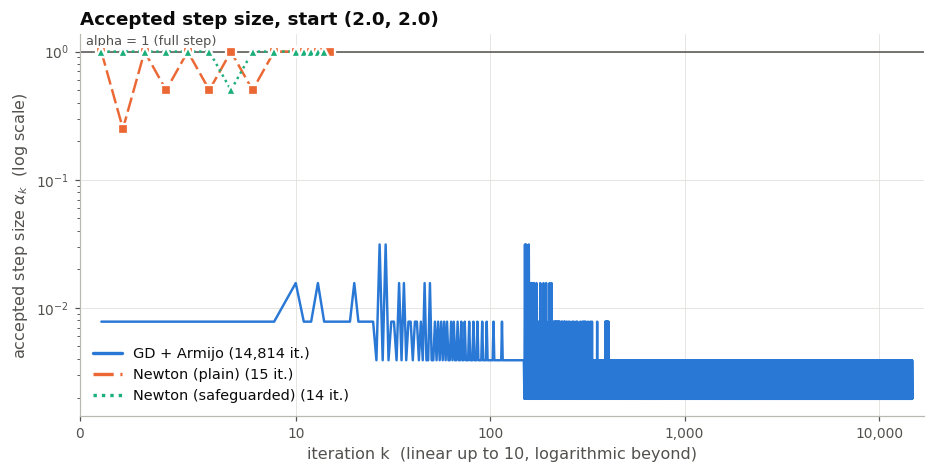

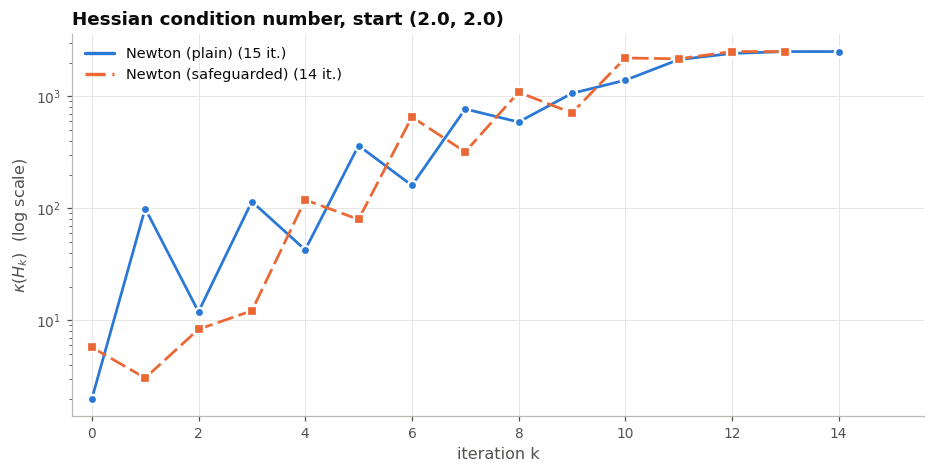

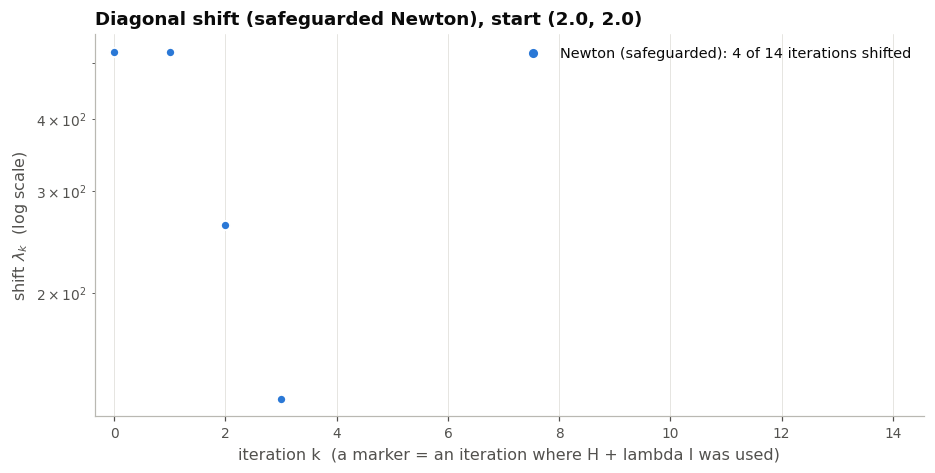

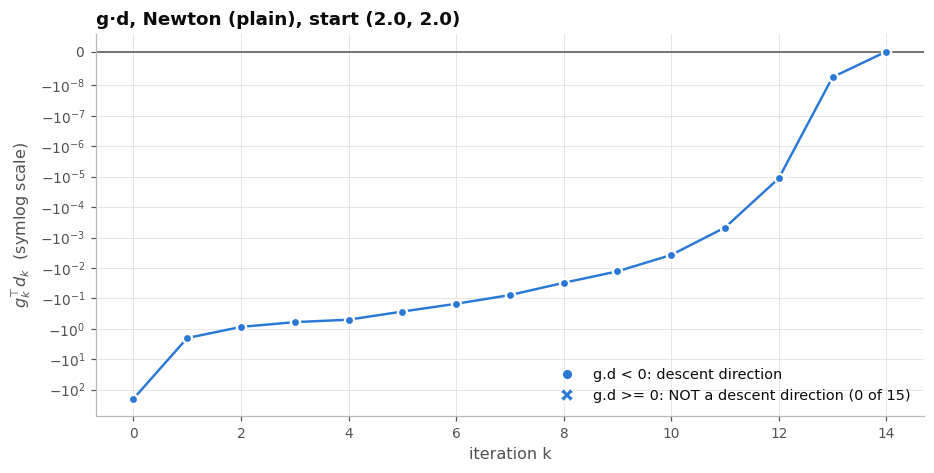

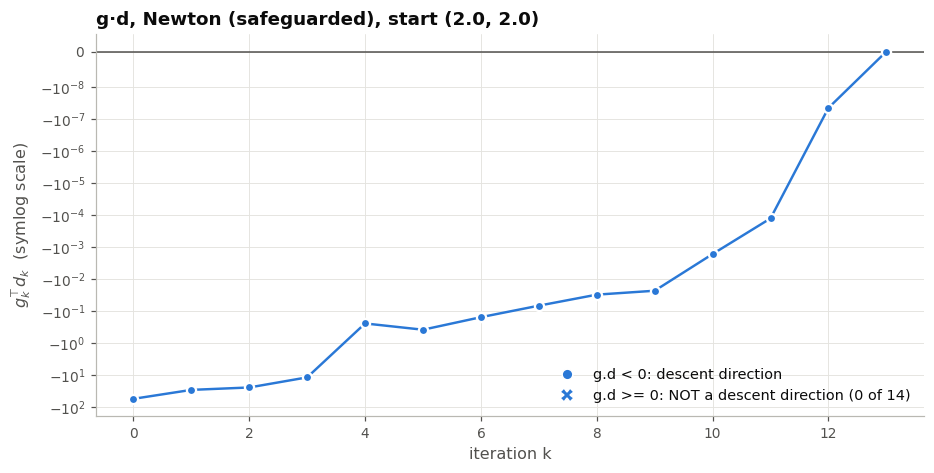

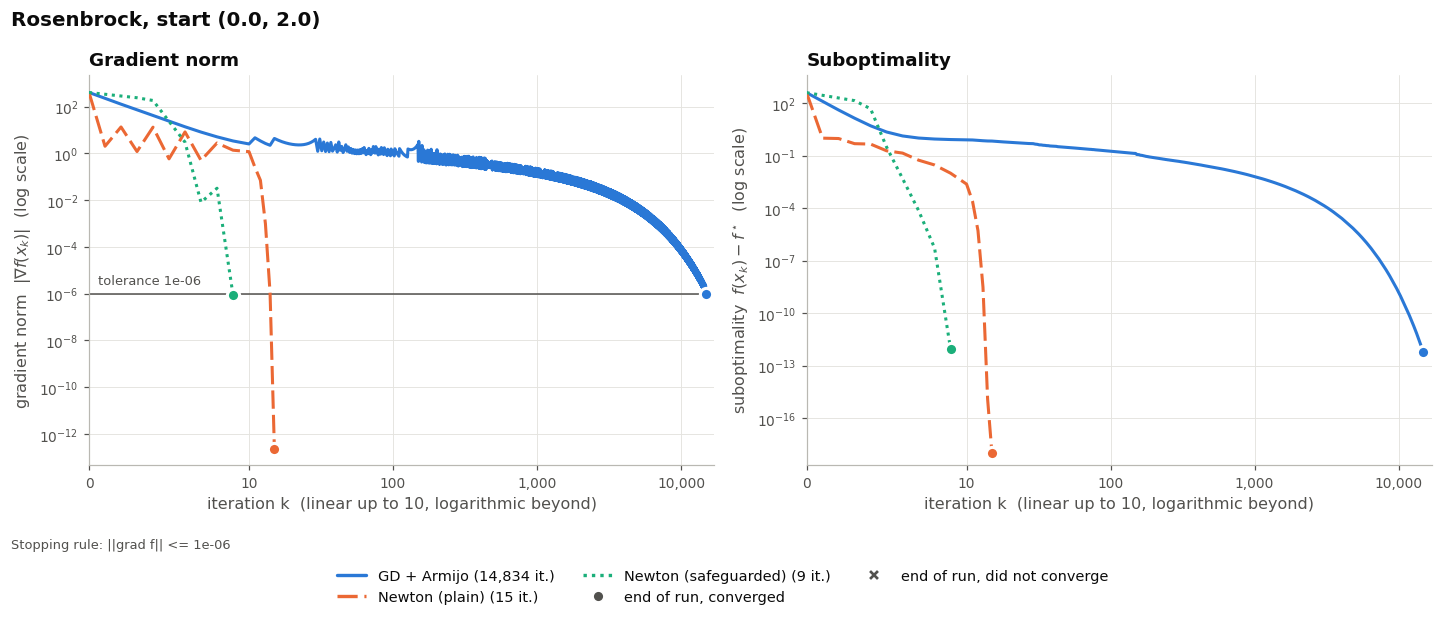

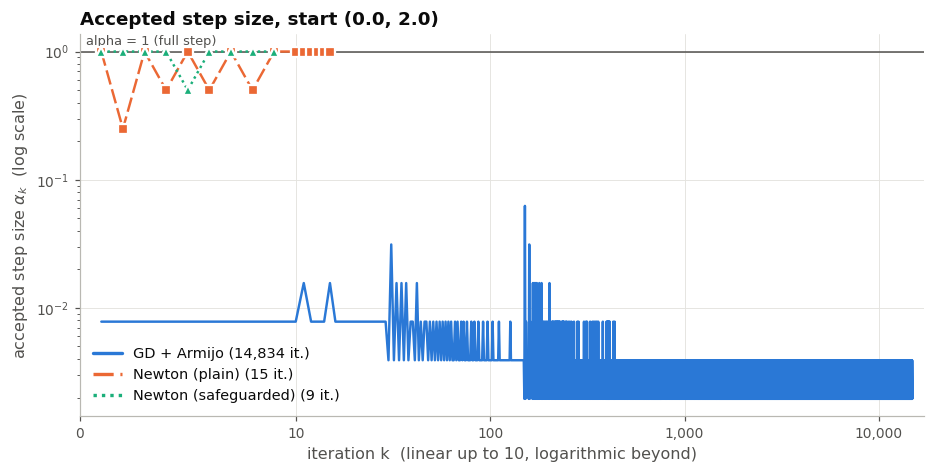

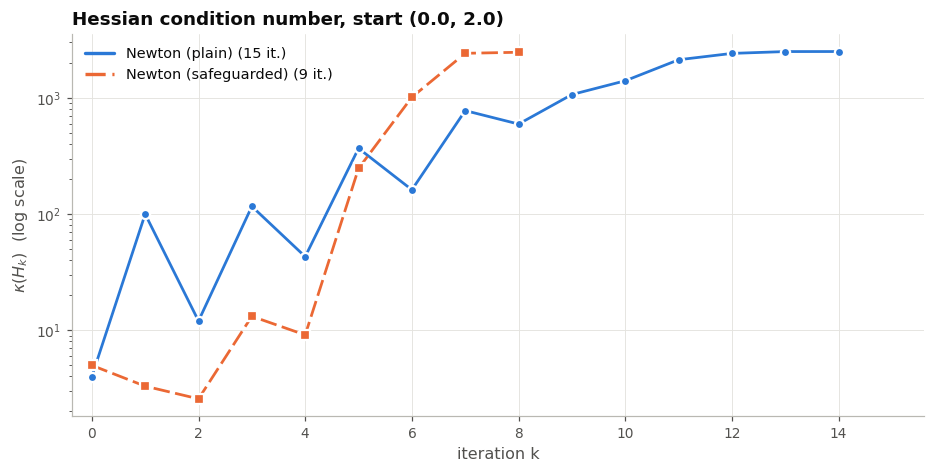

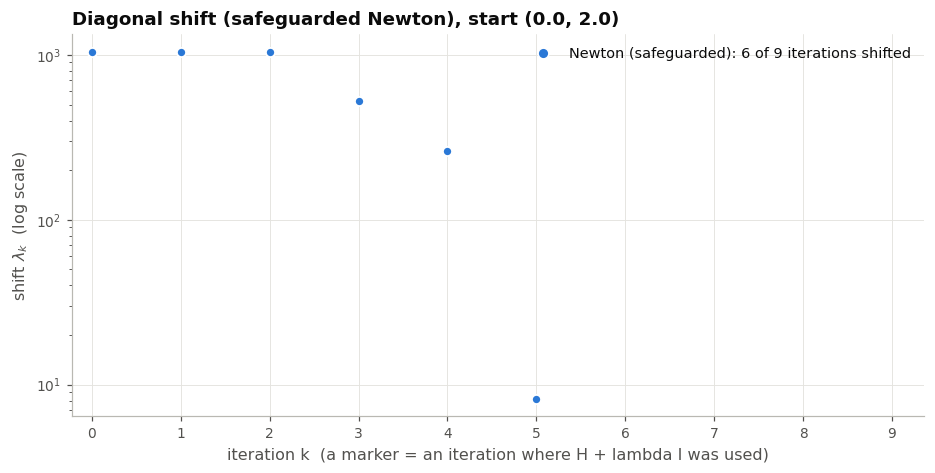

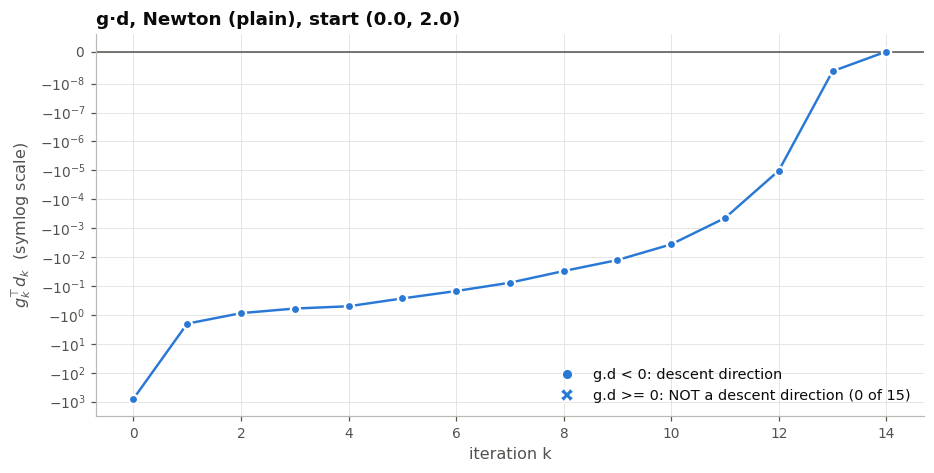

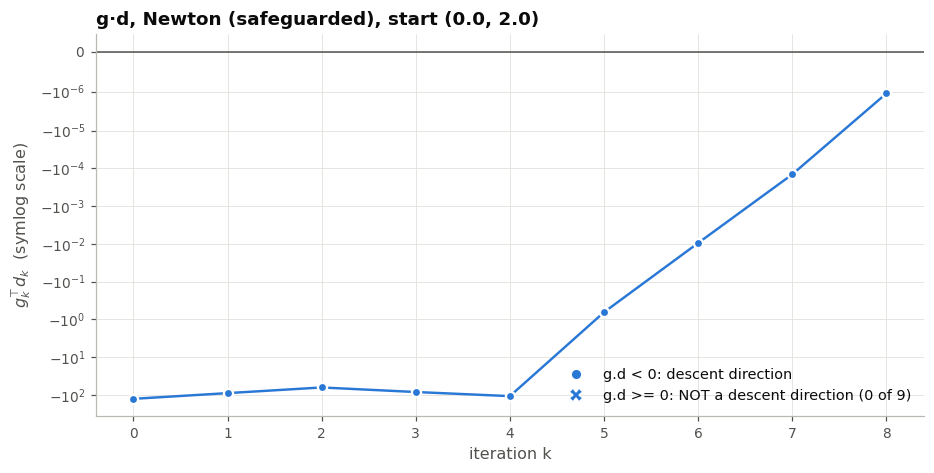

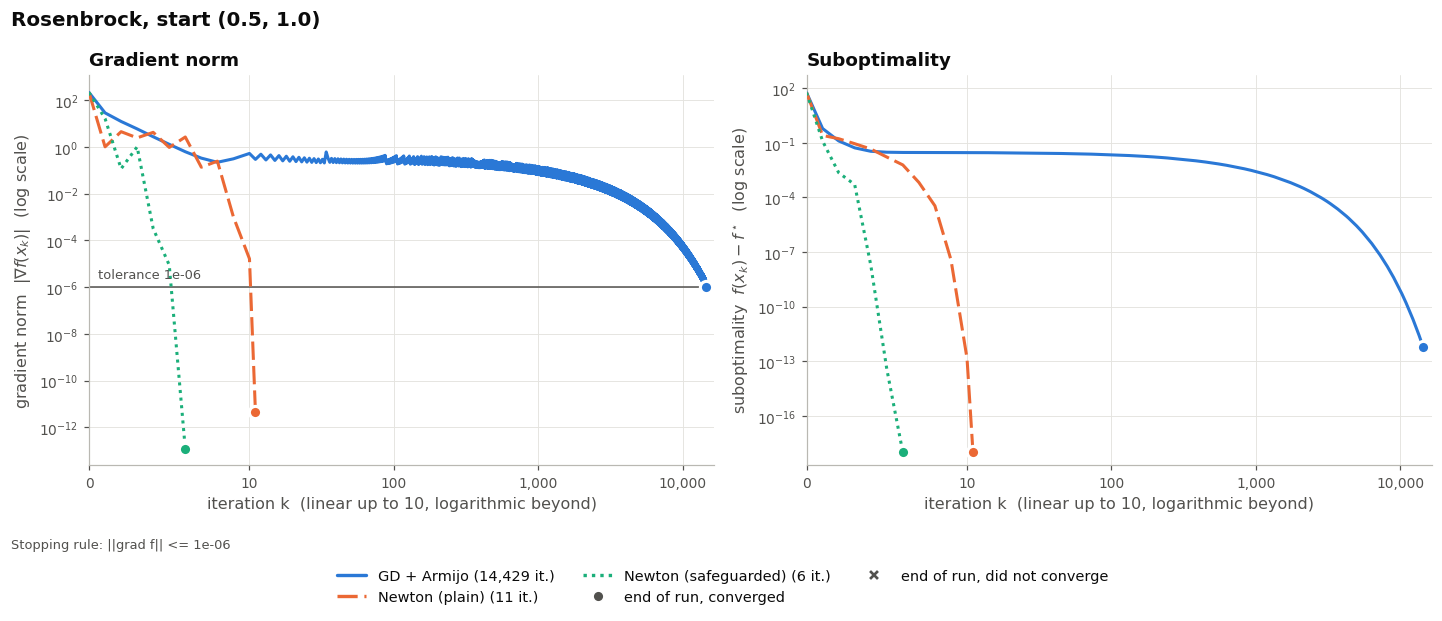

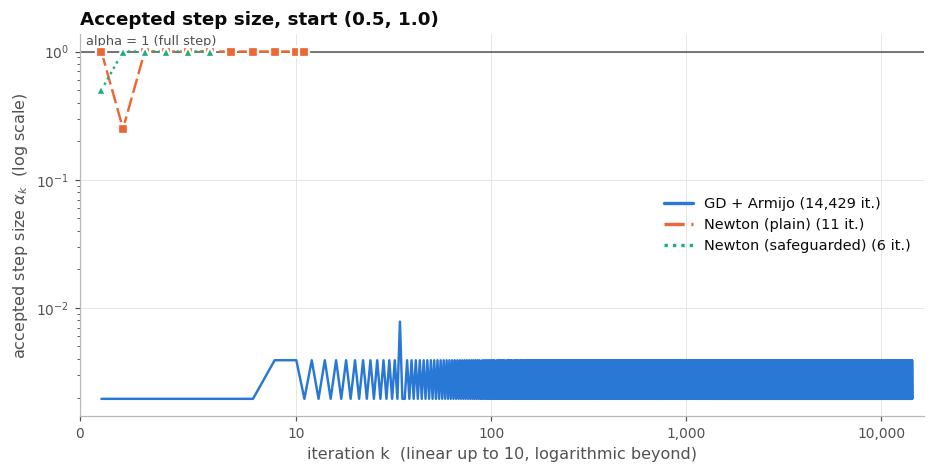

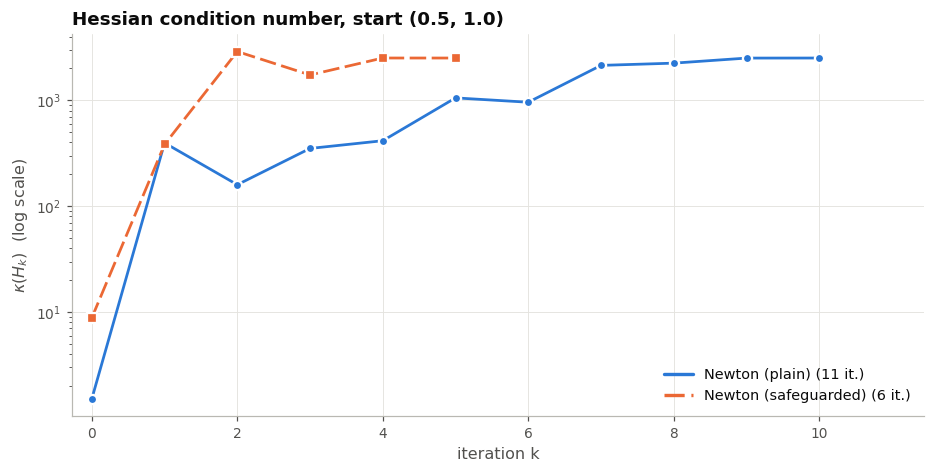

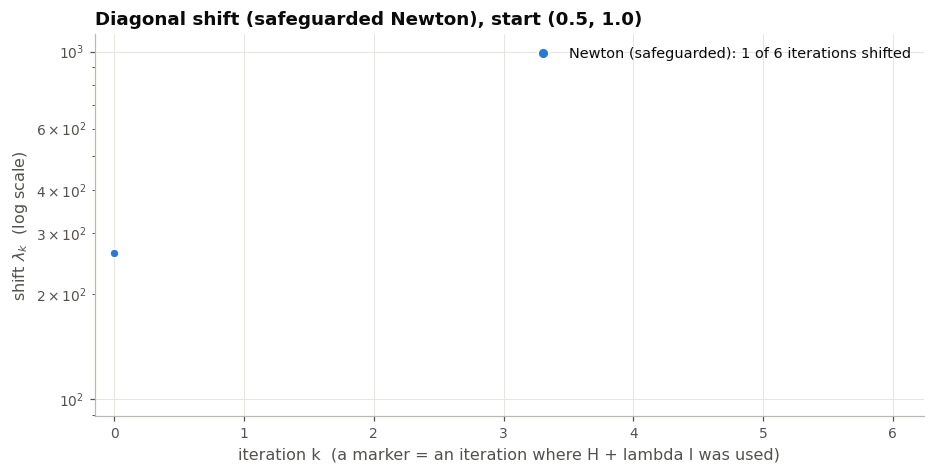

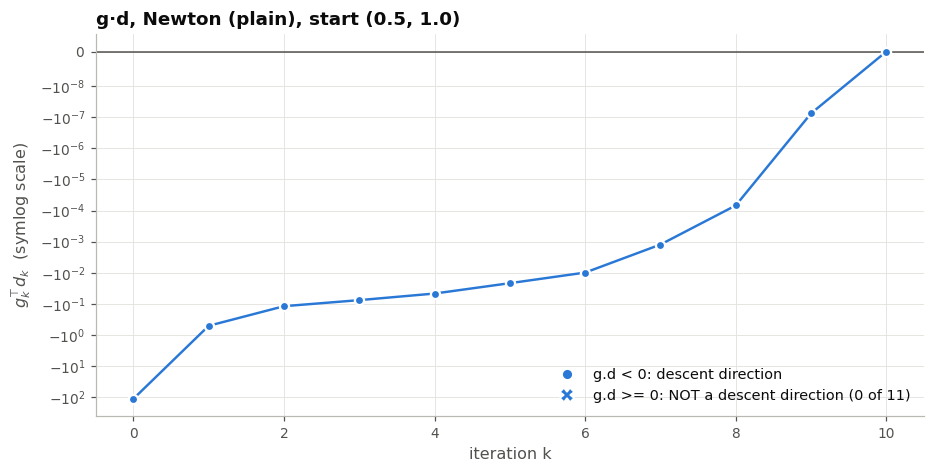

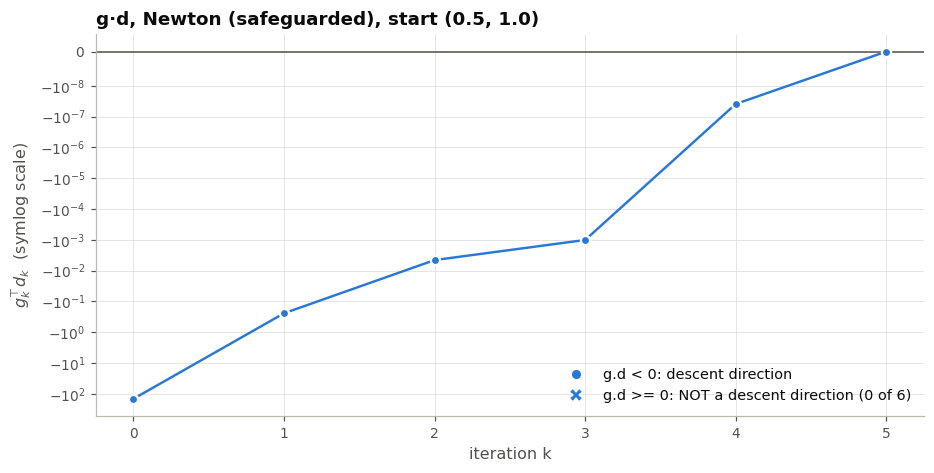

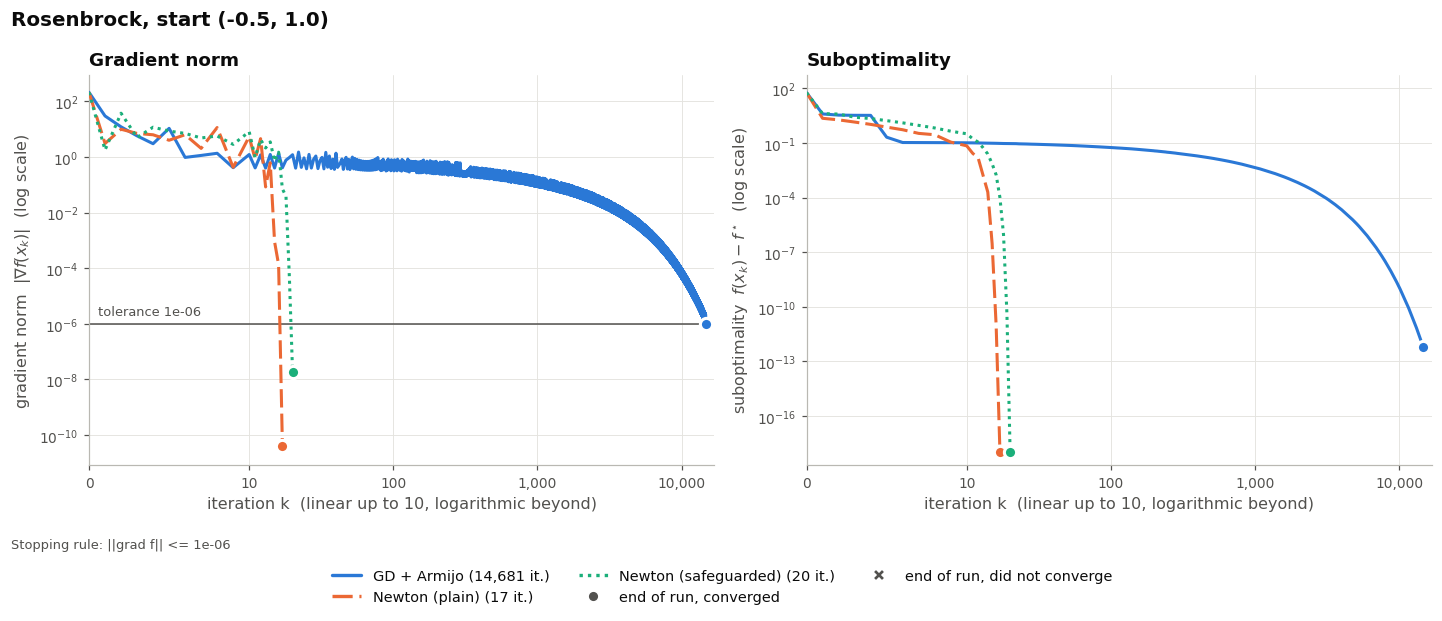

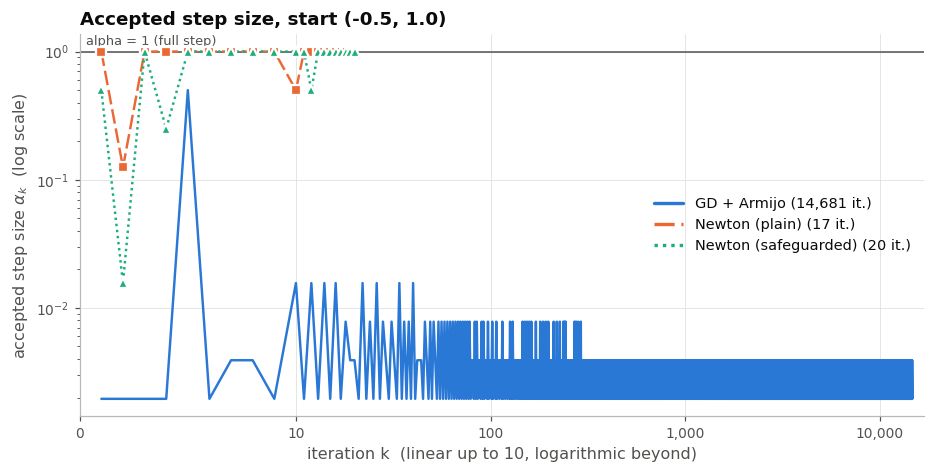

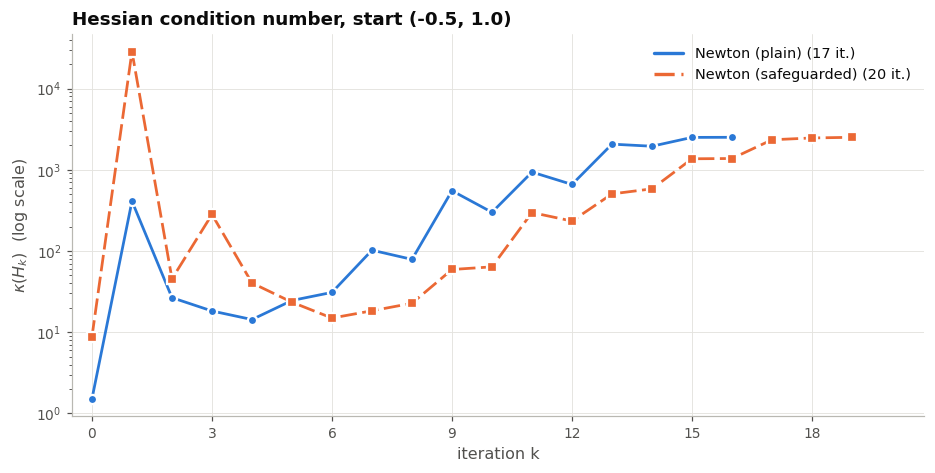

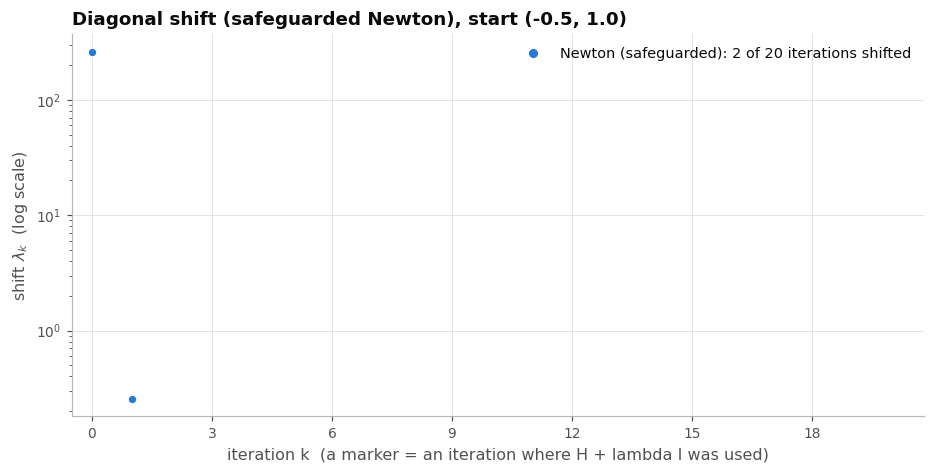

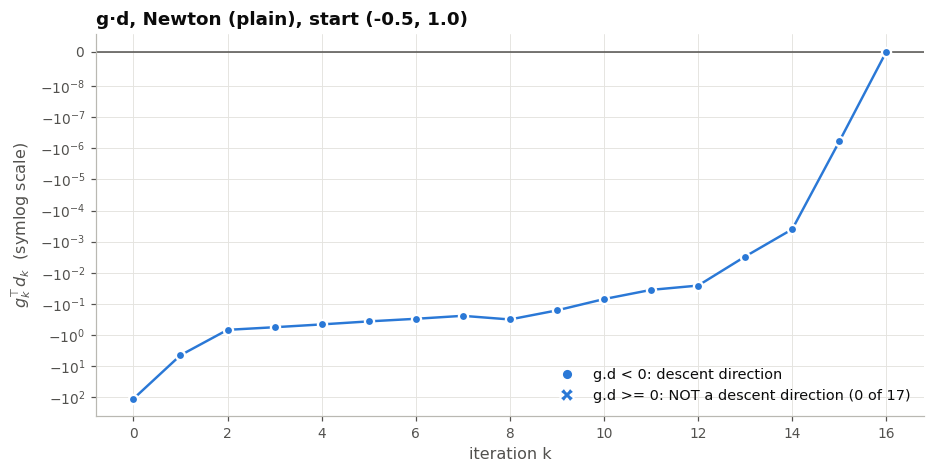

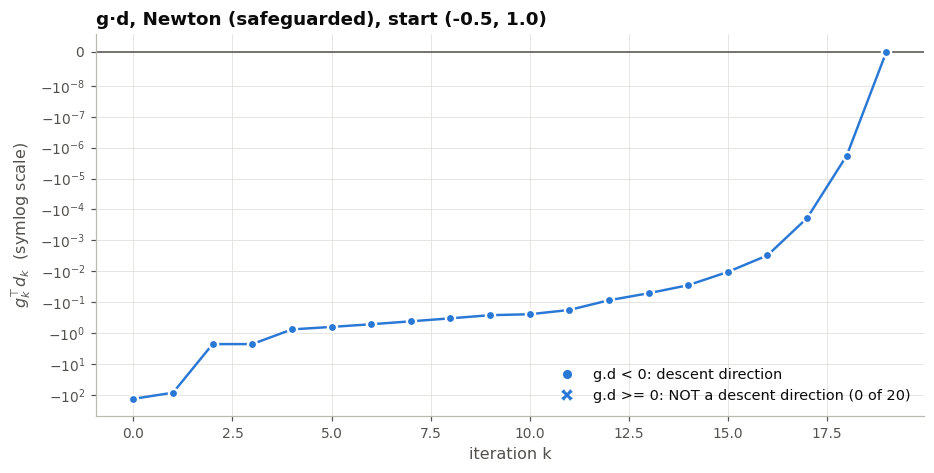

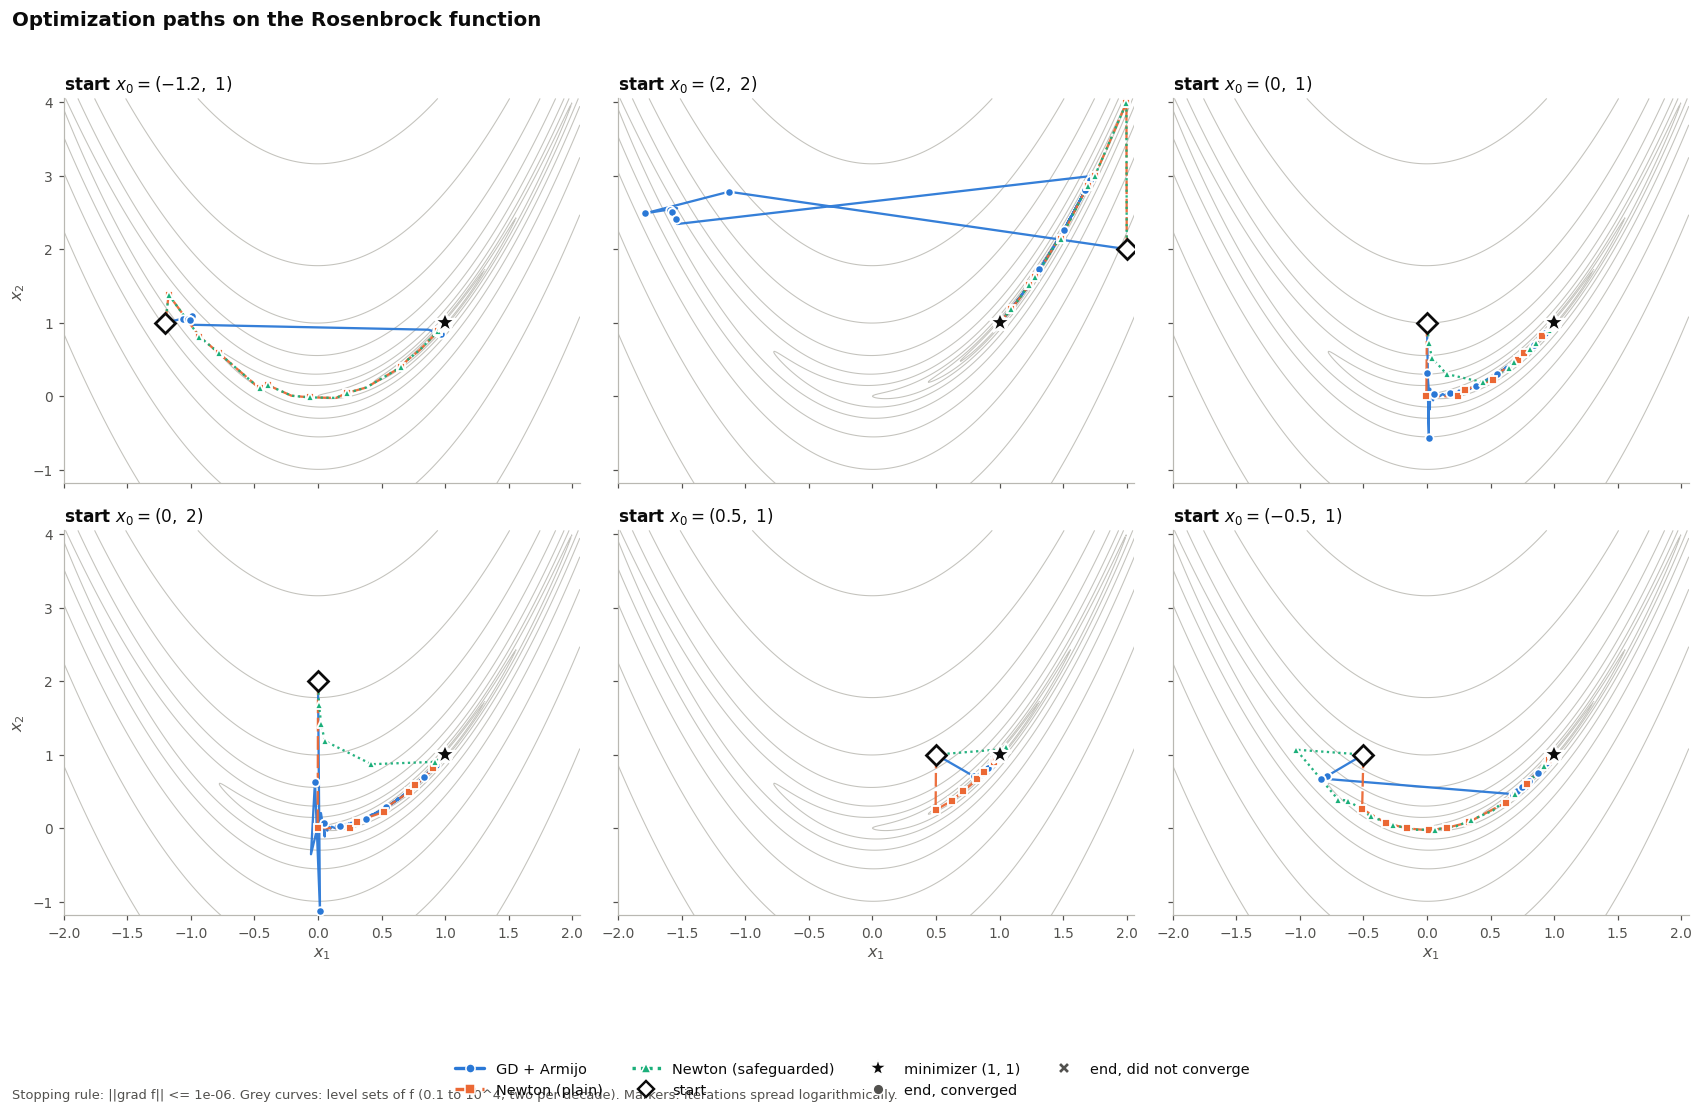

,Method,Start,Iterations,Converged,Final f,Final ||grad||,Tolerance,Step rule,Iteration cap,Non-descent steps (g.d >= 0),Iterations shifted
0,GD + Armijo,"(-1.2, 1)",13756,yes,6.120e-13,9.833e-07,1e-06,"backtracking (alpha in [0.000977, 0.5])",200000,nan,nan
1,Newton (plain),"(-1.2, 1)",21,yes,3.744e-21,4.473e-10,1e-06,"backtracking (alpha in [0.125, 1])",200,0.000000,nan
2,Newton (safeguarded),"(-1.2, 1)",21,yes,3.744e-21,4.473e-10,1e-06,"backtracking (alpha in [0.125, 1])",200,0.000000,0.000000
3,GD + Armijo,"(2, 2)",17685,yes,5.918e-13,9.884e-07,1e-06,"backtracking (alpha in [0.000488, 0.25])",200000,nan,nan
4,Newton (plain),"(2, 2)",15,yes,1.233e-28,1.192e-13,1e-06,"backtracking (alpha in [0.25, 1])",200,0.000000,nan
5,Newton (safeguarded),"(2, 2)",15,yes,1.233e-28,1.192e-13,1e-06,"backtracking (alpha in [0.25, 1])",200,0.000000,0.000000
6,GD + Armijo,"(0, 1)",14814,yes,6.270e-13,9.970e-07,1e-06,"backtracking (alpha in [0.00195, 0.0312])",200000,nan,nan
7,Newton (plain),"(0, 1)",15,yes,4.024e-28,3.654e-13,1e-06,"backtracking (alpha in [0.25, 1])",200,0.000000,nan
8,Newton (safeguarded),"(0, 1)",14,yes,1.415e-26,1.719e-13,1e-06,"backtracking (alpha in [0.5, 1])",200,0.000000,4.000000
9,GD + Armijo,"(0, 2)",14834,yes,6.123e-13,9.959e-07,1e-06,"backtracking (alpha in [0.00195, 0.0625])",200000,nan,nan


In [10]:
starts = [(-1.2, 1.0), (0.0, 1.0), (2.0, 2.0), (0.0, 2.0), (0.5, 1.0), (-0.5, 1.0)]
tol = 1e-6
gd_cap, newton_cap = 200000, 200

def pack(name, i, xs, fs, gn, al, cap, **extra):
    return make_run(name, xs[i], fs=fs[i], gnorms=gn[i], alphas=al[i],
                    tol=tol, max_iter=cap, **extra)

all_runs = []
for i, x0 in enumerate(starts):
    gd = pack("GD + Armijo", i, gd_xs, gd_fn_vals, gd_grad_norms, gd_step_sizes, gd_cap)
    nw = pack("Newton (plain)", i, nwp_xs, nwp_fn_vals, nwp_grad_norms, nwp_step_sizes, newton_cap,
              dirderivs=nwp_slopes[i], cond_numbers=nwp_condition_nos[i])    # g.d recorded BEFORE any fallback
    sf = pack("Newton (safeguarded)", i, nws_xs, nws_fn_vals, nws_grad_norms, nws_step_sizes, newton_cap,
              dirderivs=nws_slopes[i], cond_numbers=nws_condition_nos[i], shifts=nws_lambdas[i])
    all_runs += [gd, nw, sf]

    # ---- per-start figures: only three methods each ----
    plot_convergence_panel([gd, nw, sf], title=f"Rosenbrock, start {x0}",
                           save=f"partB_conv_{i}.png")                        # grad norm and f - f*
    plot_step_sizes([gd, nw, sf], title=f"Accepted step size, start {x0}",
                    save=f"partB_alpha_{i}.png")
    plot_condition_numbers([nw, sf], title=f"Hessian condition number, start {x0}",
                           save=f"partB_cond_{i}.png")
    plot_shifts([sf], title=f"Diagonal shift (safeguarded Newton), start {x0}",
                save=f"partB_shifts_{i}.png")
    for r in (nw, sf):
        plot_descent_check(r, title=f"g·d, {r.name}, start {x0}",
                           save=f"partB_descent_{i}_{'plain' if r is nw else 'safeguarded'}.png")

# ---- figures and tables across all starts ----
plot_rosenbrock_paths(all_runs, save="partB_paths.png")     # one panel per start, all methods overlaid
summary_table(all_runs)                                     # one row per (method, start)

1. When is a plain Newton step not a descent direction, and how did you detect it?

    The dot product of the descent direction and the gradient is positive that means the descent direction points in a direction of increase.

2. For Rosenbrock, where did safeguarded Newton help, and where did it behave like GD?

    Safeguarded Newton helped (in terms of fewer iterations) for (0, 2) and (0.5, 1). It increased the iterations for (-0.5, 1). For the point (0, 2), safeguarded Newton and GD had similar values for the function value and the gradient norm at the end, although the number of iterations it took were far less than what GD took. In no case a non-descent direction was observed.

3. Newton uses fewer iterations. Is it always cheaper? Compare the cost per iteration with GD.

    At each step Newton solves a matrix vector equation and also does cholesky decomposition if safeguard is applied. The cholesky decomposition is run multiple times till the modified hessian becomes positive definite. Gradient descent does not involve these computations. Per iteration, Newton is more expensive than Gradient descent.

4. How did kappa affect each method in Part A?

    In part A, kappa affected only gradient descent. Its iterations increased with a power law relation to the condition number. Newton method was unaffected.